In [1]:
# loading the training data
import pandas as pd
df = pd.read_csv("../data/synthetic_employee_welfare.csv")
df.head()

,employee_id,age,gender,department,marital_status,number_of_dependents,children_count,elderly_dependents,is_sandwich,caregiving_responsibility,...,health_concern,bereavement_recent,marriage_recent,birth_recent,divorce_recent,elderly_care_need,education_support_need,financial_program_used,family_support_used,counselling_used
0,EMP00001,46,Male,Finance,Single,5,4,1,1,0,...,0,0,0,0,0,0,1,1,1,0
1,EMP00002,44,Male,HR,Married,6,4,2,1,1,...,1,0,0,0,0,0,1,1,1,0
2,EMP00003,28,Female,Finance,Single,1,1,0,0,0,...,0,0,0,0,0,0,1,1,0,0
3,EMP00004,44,Male,IT,Married,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,EMP00005,39,Female,Marketing,Single,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1


In [2]:
# confirming how realistic the data is
df["marital_status"].value_counts()

marital_status
Married     997
Single      757
Divorced    162
Widowed      84
Name: count, dtype: int64

In [3]:
# Check the dataset structure
df.shape
#500 rows and 21 columns

(2000, 22)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 22 columns):
 #   Column                     Non-Null Count  Dtype 
---  ------                     --------------  ----- 
 0   employee_id                2000 non-null   object
 1   age                        2000 non-null   int64 
 2   gender                     2000 non-null   object
 3   department                 2000 non-null   object
 4   marital_status             2000 non-null   object
 5   number_of_dependents       2000 non-null   int64 
 6   children_count             2000 non-null   int64 
 7   elderly_dependents         2000 non-null   int64 
 8   is_sandwich                2000 non-null   int64 
 9   caregiving_responsibility  2000 non-null   int64 
 10  financial_difficulty       2000 non-null   int64 
 11  mental_wellbeing_concern   2000 non-null   int64 
 12  health_concern             2000 non-null   int64 
 13  bereavement_recent         2000 non-null   int64 
 14  marriage

In [5]:
df.isnull().sum()

employee_id                  0
age                          0
gender                       0
department                   0
marital_status               0
number_of_dependents         0
children_count               0
elderly_dependents           0
is_sandwich                  0
caregiving_responsibility    0
financial_difficulty         0
mental_wellbeing_concern     0
health_concern               0
bereavement_recent           0
marriage_recent              0
birth_recent                 0
divorce_recent               0
elderly_care_need            0
education_support_need       0
financial_program_used       0
family_support_used          0
counselling_used             0
dtype: int64

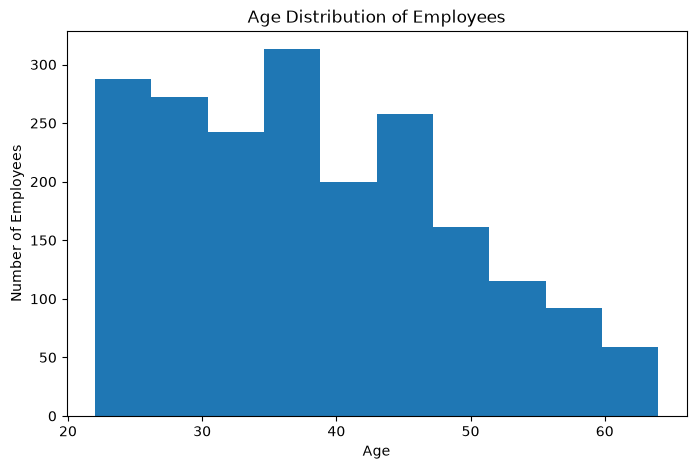

In [6]:
#Visualize age
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.hist(df["age"], bins=10)
plt.xlabel("Age")
plt.ylabel("Number of Employees")
plt.title("Age Distribution of Employees")
plt.show()

Check the categorical distributions

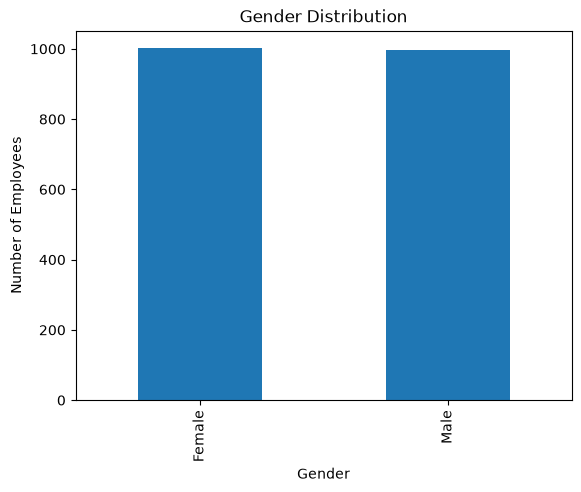

In [7]:
# Gender
df["gender"].value_counts().plot(kind="bar")

plt.title("Gender Distribution")
plt.xlabel("Gender")
plt.ylabel("Number of Employees")

plt.show()

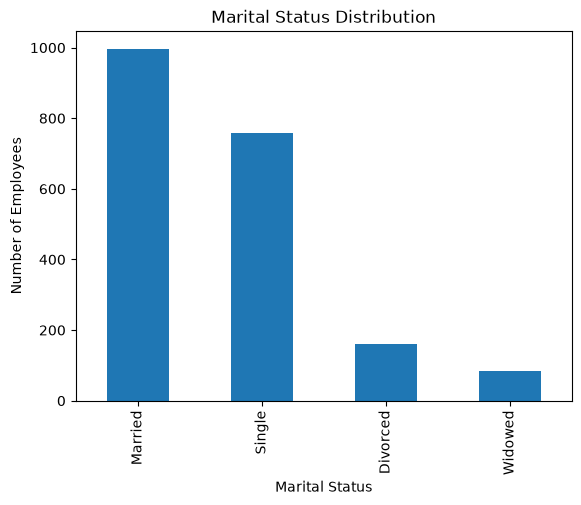

In [8]:
#Marital status
df["marital_status"].value_counts().plot(kind="bar")

plt.title("Marital Status Distribution")
plt.xlabel("Marital Status")
plt.ylabel("Number of Employees")

plt.show()

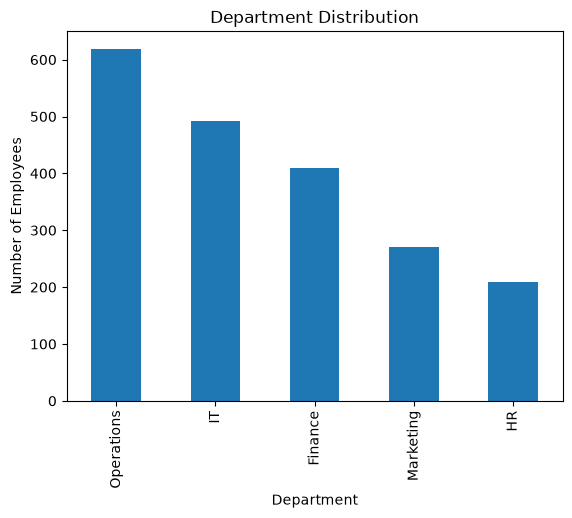

In [9]:
#Department
df["department"].value_counts().plot(kind="bar")

plt.title("Department Distribution")
plt.xlabel("Department")
plt.ylabel("Number of Employees")

plt.show()

Data preprocessing

In [10]:
# ============================================================
# Clustering features
#
# 8 features aligned with the proposal:
#   - dependent burden
#   - caregiving responsibility
#   - financial pressure
#   - welfare needs
#   - recent life event (bereavement)
#
# Demographic columns (age, gender, department, marital_status)
# are kept in the CSV for the recommendation layer and HR
# dashboard, but are NOT used for clustering.
# ============================================================

clustering_features = [
    "number_of_dependents",
    "children_count",
    "elderly_dependents",
    "caregiving_responsibility",
    "financial_difficulty",
    "elderly_care_need",
    "education_support_need",
    "bereavement_recent",
]

X = df[clustering_features].copy()

X.head()

,number_of_dependents,children_count,elderly_dependents,caregiving_responsibility,financial_difficulty,elderly_care_need,education_support_need,bereavement_recent
0,5,4,1,0,1,0,1,0
1,6,4,2,1,1,0,1,0
2,1,1,0,0,0,0,1,0
3,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0


Scale the features

In [11]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

X_scaled.shape

(2000, 8)

Find the number of clusters

In [12]:
# Elbow Method
from sklearn.cluster import KMeans

inertia = []

for k in range(2, 8):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)

    inertia.append(kmeans.inertia_)

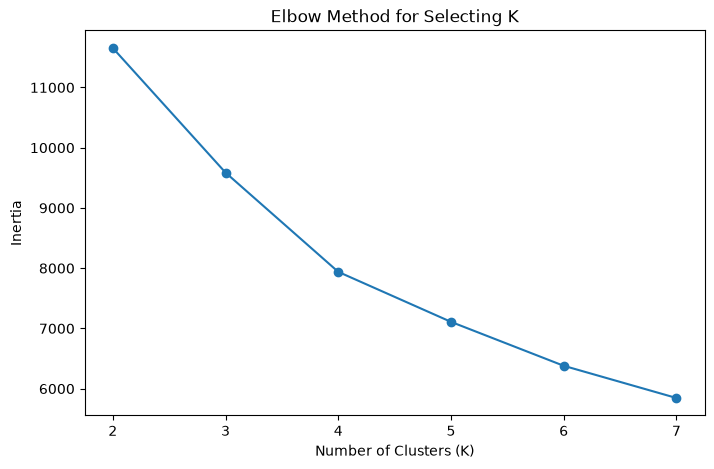

In [13]:
# Plotting it
plt.figure(figsize=(8, 5))

plt.plot(range(2, 8), inertia, marker="o")

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Selecting K")

plt.show()

In [14]:
# Silhouette score
from sklearn.metrics import silhouette_score

silhouette_scores = []

for k in range(2, 8):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, labels)

    silhouette_scores.append(score)

    print(f"K = {k}, Silhouette Score = {score:.3f}")

K = 2, Silhouette Score = 0.298
K = 3, Silhouette Score = 0.294
K = 4, Silhouette Score = 0.322
K = 5, Silhouette Score = 0.316
K = 6, Silhouette Score = 0.335
K = 7, Silhouette Score = 0.352


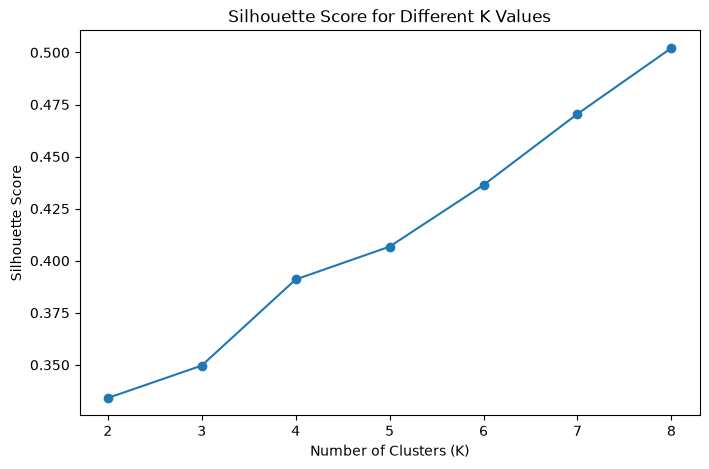

In [34]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(2, 9),
    silhouette_scores,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score for Different K Values")

plt.show()

In [35]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=8, random_state=42, n_init=10)

clusters = kmeans.fit_predict(X_scaled)

df["cluster"] = clusters

df["cluster"].value_counts().sort_index()

cluster
0    650
1    140
2    222
3    215
4    239
5    106
6    273
7    155
Name: count, dtype: int64

In [16]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

df = pd.read_csv(r"C:\Users\wendy\OneDrive\Desktop\Employee Welfare Recomendation System\employee-welfare-system\machine-learning\data\synthetic_employee_welfare.csv")
features = [
    "number_of_dependents",
    "children_count",
    "elderly_dependents",
    "caregiving_responsibility",
    "financial_difficulty",
    "elderly_care_need",
    "education_support_need",
    "bereavement_recent",
]

X = df[features]
X_scaled = StandardScaler().fit_transform(X)

km = KMeans(n_clusters=4, random_state=42, n_init=10)
df["cluster"] = km.fit_predict(X_scaled)

print("Cluster sizes:")
print(df["cluster"].value_counts().sort_index())

print("\nCluster centroids:")
centroids = pd.DataFrame(
    StandardScaler().fit(X).inverse_transform(km.cluster_centers_),
    columns=features
)
print(centroids.round(3))

print("\nPer-cluster averages:")
for col in features:
    print(f"\n{col}:")
    print(df.groupby("cluster")[col].mean().round(3))

Cluster sizes:
cluster
0    635
1    448
2    832
3     85
Name: count, dtype: int64

Cluster centroids:
   number_of_dependents  children_count  elderly_dependents  \
0                 2.649           2.272               0.376   
1                 3.042           1.663               1.379   
2                 0.540           0.431               0.108   
3                 2.576           1.682               0.894   

   caregiving_responsibility  financial_difficulty  elderly_care_need  \
0                      0.435                 0.457              0.000   
1                      0.600                 0.431              0.940   
2                      0.063                 0.207             -0.000   
3                      0.459                 0.353              0.459   

   education_support_need  bereavement_recent  
0                   0.674                 0.0  
1                   0.406                 0.0  
2                   0.070                 0.0  
3                   0

In [20]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# --- Load ---
df = pd.read_csv(
    r"C:\Users\wendy\OneDrive\Desktop\Employee Welfare Recomendation System\employee-welfare-system\machine-learning\data\synthetic_employee_welfare.csv"
)

# --- Features ---
features = [
    "number_of_dependents",
    "children_count",
    "elderly_dependents",
    "caregiving_responsibility",
    "financial_difficulty",
    "elderly_care_need",
    "education_support_need",
    "bereavement_recent",
]

X = df[features]
X_scaled = StandardScaler().fit_transform(X)

# --- Train K=4 ---
km = KMeans(n_clusters=4, random_state=42, n_init=10)
df["cluster"] = km.fit_predict(X_scaled)

# --- Save so downstream scripts can use it ---
df.to_csv(
    r"C:\Users\wendy\OneDrive\Desktop\Employee Welfare Recomendation System\employee-welfare-system\machine-learning\data\employees_with_clusters.csv",
    index=False
)
# --- Report ---
print("=" * 60)
print("K=4 CLUSTER DIAGNOSTIC")
print("=" * 60)

print("\nCluster sizes:")
print(df["cluster"].value_counts().sort_index())

print("\nCluster profiles (mean per cluster):")
print(df.groupby("cluster")[features].mean().round(2))

print("\nLife events by cluster (%):")
for event in ["bereavement_recent", "divorce_recent", "marriage_recent", "birth_recent"]:
    print(f"\n{event}:")
    print((df.groupby("cluster")[event].mean() * 100).round(1))

# --- Sample employee from each cluster ---
print("\n" + "=" * 60)
print("SAMPLE EMPLOYEE FROM EACH CLUSTER")
print("=" * 60)

for c in sorted(df["cluster"].unique()):
    sample = df[df["cluster"] == c].iloc[0]
    print(f"\nCluster {c}: {sample['employee_id']}")
    print(f"   Dependents: {sample['number_of_dependents']} "
          f"(children={sample['children_count']}, elderly={sample['elderly_dependents']})")
    print(f"   Caregiving: {sample['caregiving_responsibility']}  "
          f"Financial: {sample['financial_difficulty']}")
    print(f"   Eldercare need: {sample['elderly_care_need']}  "
          f"Education need: {sample['education_support_need']}")
    print(f"   Bereavement: {sample['bereavement_recent']}  "
          f"Divorce: {sample['divorce_recent']}")

K=4 CLUSTER DIAGNOSTIC

Cluster sizes:
cluster
0    635
1    448
2    832
3     85
Name: count, dtype: int64

Cluster profiles (mean per cluster):
         number_of_dependents  children_count  elderly_dependents  \
cluster                                                             
0                        2.65            2.27                0.38   
1                        3.04            1.66                1.38   
2                        0.54            0.43                0.11   
3                        2.58            1.68                0.89   

         caregiving_responsibility  financial_difficulty  elderly_care_need  \
cluster                                                                       
0                             0.43                  0.46               0.00   
1                             0.60                  0.43               0.94   
2                             0.06                  0.21               0.00   
3                             0.46         